# Generate AR6 equivalent values of the different scenario approaches
This code loads the AR6 database and uses it to calculate the remaining carbon budgets according to the FaIR and MAGICC calibrations. It generates the table of values that take the scenario approaches 2 and 3 (exceedance and peak warming). 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pyam
import numpy as np
import os
from scipy.stats import linregress
import seaborn as sns

<IPython.core.display.Javascript object>

In [2]:
# Import data
ar6meta = pd.read_excel("./input/AR6_Scenarios_Database_metadata_indicators_v1.1.xlsx", sheet_name="meta_Ch3vetted_withclimate")
ar6meta = ar6meta.rename(columns={"Scenario": "scenario", "Model": "model"}).set_index(["model", "scenario"])

In [3]:
ar6 = pyam.IamDataFrame("./input/AR6_Scenarios_Database_World_v1.1.csv", meta=ar6meta)
ar6harm = pyam.IamDataFrame("./input/1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv", meta=ar6meta)

pyam.core - INFO: Reading file input\AR6_Scenarios_Database_World_v1.1.csv
C:\Users\rlamb\anaconda3\envs\silicone-3\Lib\site-packages\pyam\utils.py:340: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=True)
pyam.core - INFO: Reading file input\1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv
C:\Users\rlamb\anaconda3\envs\silicone-3\Lib\site-packages\pyam\utils.py:340: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=True)


In [4]:
infillstring = "AR6 climate diagnostics|Harmonized|"
co2 = "Emissions|CO2"
eni = "|Energy and Industrial Processes"
afolu = "|AFOLU"

useful = ar6harm.filter(variable=infillstring + co2 + "*").add(
    infillstring+co2+eni, infillstring+co2+afolu, co2, ignore_units=True
)

pyam.plotting - INFO: >=13 labels, not applying legend


<Axes: title={'center': 'region: World - variable: Emissions|CO2'}, xlabel='Year', ylabel='unknown'>

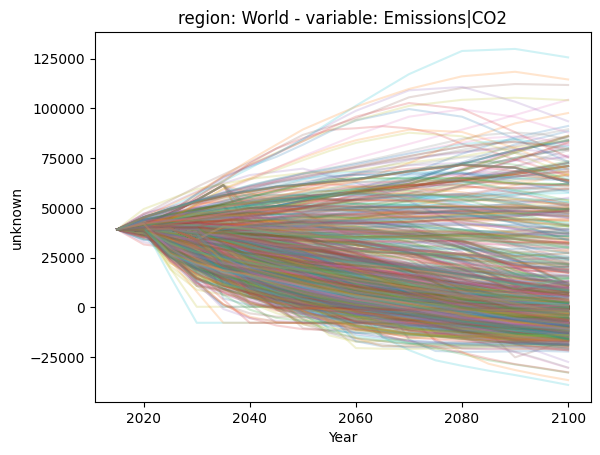

In [5]:
useful.filter(variable=co2).plot(alpha=0.2)

In [6]:
useful.filter(year=2015).timeseries()[2015].unique()

array([39152.7263, 39152.7263, 39152.7263])

In [7]:
tempfair = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile'
tempmagicc = 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile'
tempfair83 = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|83.3th Percentile'
tempfair66 = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|67.0th Percentile'
tempmagicc83 = 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|83.3th Percentile'
tempmagicc66 = 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|67.0th Percentile'

In [8]:
useful = pyam.concat([useful, ar6.filter(variable=[tempfair, tempmagicc, tempfair83, tempfair66, tempmagicc83, tempmagicc66])])

In [9]:
useful.variable

['AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile',
 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|67.0th Percentile',
 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|83.3th Percentile',
 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile',
 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|67.0th Percentile',
 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|83.3th Percentile',
 'Emissions|CO2']

In [10]:
useful = useful.interpolate(time=range(2015, 2101)).filter(year=range(2015, 2101))

pyam.plotting - INFO: >=13 labels, not applying legend


<Axes: title={'center': 'region: World - variable: AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile'}, xlabel='Year', ylabel='K'>

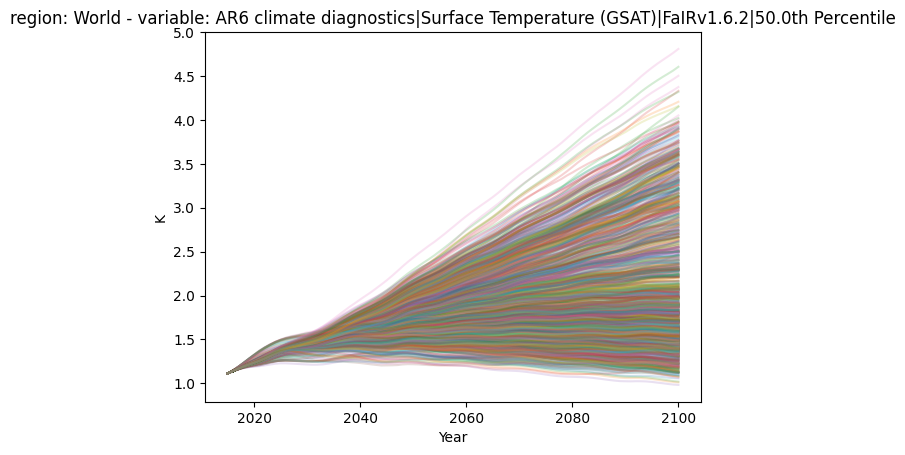

In [11]:
useful.filter(variable=tempfair).plot(alpha=0.2)

In [12]:
assert useful.timeseries().isna().sum().sum() == 0
useful_ts = useful.timeseries().reset_index().drop(columns=["unit"])

In [13]:
def make_long(df):
    # This flips a dataframe to have different variable names as the columns and 
    # model/scenario/years as rows
    return df.melt(
        id_vars=["model", "scenario", "region", "variable"], 
        var_name="year", 
        value_name="value"
    ).pivot_table(
        index=["model", "scenario", "region", "year"], 
        columns="variable", 
        values="value"
    )

In [14]:
useful_long = make_long(useful_ts)

In [15]:
cumco2 = "Cumulative CO2"
useful_long[cumco2] = useful_long.groupby(["model", "scenario", "region"])[co2].cumsum()

In [16]:
useful_long

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.111952                                 
                                                2016                                           1.140040                                 
                                                2017                                           1.167576                                 
                                                2018                                           1.193959                                 
                                                2019                                           1.218368                                 
...                                                                                                 ...                                 
WITCH-GLOBIOM 4.4 CD-LINKS_NoPolicy      World  2096                                           3.593418                                 
                                                2097                                           3.622228                                 
                                                2098                                           3.650265                                 
                                                2099                                           3.679157                                 
                                                2100                                           3.710858                                 

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|67.0th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.171397                                 
                                                2016                                           1.200596                                 
                                                2017                                           1.227560                                 
                                                2018                                           1.255157                                 
                                                2019                                           1.281616                                 
...                                                                                                 ...                                 
WITCH-GLOBIOM 4.4 CD-LINKS_NoPolicy      World  2096                                           3.906194                                 
                                                2097                                           3.935994                                 
                                                2098                                           3.966350                                 
                                                2099                                           3.997770                                 
                                                2100                                           4.032936                                 

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|83.3th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.231521                                 
                         

# Investigate the impact of this on carbon budgets

In [17]:
def fit_and_predict(df, x_col, y_col, x_list):
    # We use this function where we want to plot a linear relationship  
    # between variables given by columns x_col and y_col in the 
    # dataframe df and find the results for x values given by x_list
    
    df = df[[x_col, y_col]].dropna().sort_values(by=x_col)  # Clean and sort data
    slope, intercept, _, _, _ = linregress(df[x_col], df[y_col])  # Linear regression

    predict = lambda x: slope * x + intercept  # Prediction function
    y_preds = {x: predict(x) for x in x_list}

    # Plot these
    plt.scatter(df[x_col], df[y_col], label="Data", color="blue", alpha=0.05)
    plt.plot(df[x_col], predict(df[x_col]), label=f"Fit: y = {slope:.2f}x + {intercept:.2f}", color="orange")
    plt.scatter(x_list, [predict(x) for x in x_list], color="orange", label="Predictions", marker="x", s=50.0)
    plt.xlabel(x_col), plt.ylabel(y_col), plt.legend(), plt.title("Linear Fit"), plt.grid(True)
    plt.show()

    return y_preds

def fit_around_window_with_correction(df, temp_list, window, x, y_list, TCRE):
    # Find the average x of rows with y values within "window" of a chosen
    # temperature after correcting for the distance between the central
    # value and the precise value of y with the trend line TCRE.
    # df: the dataframe to find values in.
    # temp_list: central temperatures in the "window".
    # x: the column name of the x-axis, whose average we wish to find
    # y_list: the temperature column names for each item in temp_list.
    # TCRE: the control variable for correcting for subtle differences.
    z = 'Corrected cumulative net CO2'
    to_return = []
    assert len(temp_list) == len(y_list)
    for temp, y in zip(temp_list, y_list):
        validScens = df[abs(df[y] - temp) < window].copy()
        validScens[z] = validScens[x] - (validScens[y] - temp) / TCRE
        plt.scatter(validScens[x], validScens[y], alpha=0.3, c="blue")
        plt.scatter(
            validScens[z], [temp]*validScens.shape[0], alpha=0.3, c="green"
        )
        to_return += [validScens[z].mean()]
    return to_return

In [18]:
useful_long.columns

Index(['AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile',
       'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|67.0th Percentile',
       'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|83.3th Percentile',
       'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile',
       'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|67.0th Percentile',
       'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|83.3th Percentile',
       'Emissions|CO2', 'Cumulative CO2'],
      dtype='object', name='variable')

[681610.7250210214]

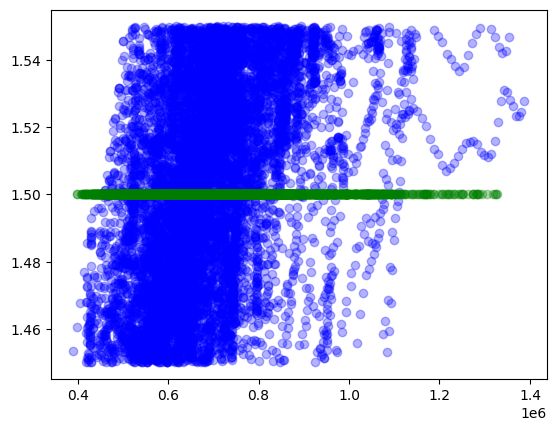

In [19]:
fit_around_window_with_correction(useful_long, [1.5], 0.05, cumco2, [tempmagicc], 0.45*1e-6)

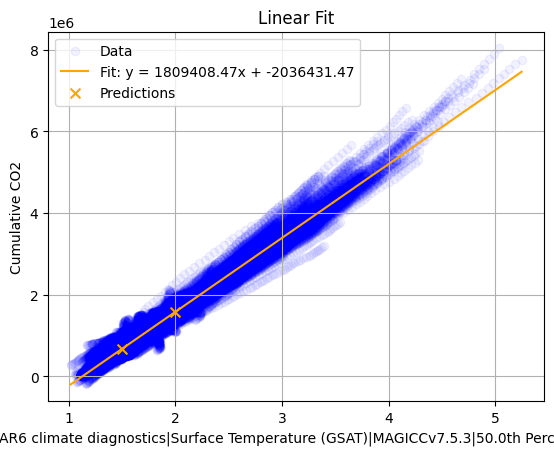

{1.5: 677681.2329629827, 2.0: 1582385.466100785}

In [20]:
temps_of_int = [1.5, 2.0]
cox_budget_magicc_unround = fit_and_predict(useful_long, tempmagicc, cumco2, temps_of_int)
cox_budget_magicc_unround

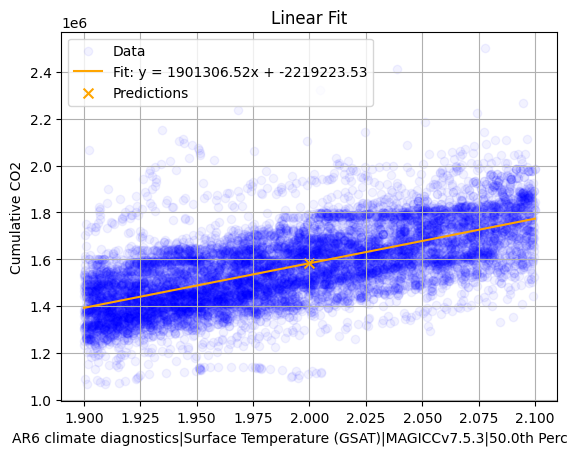

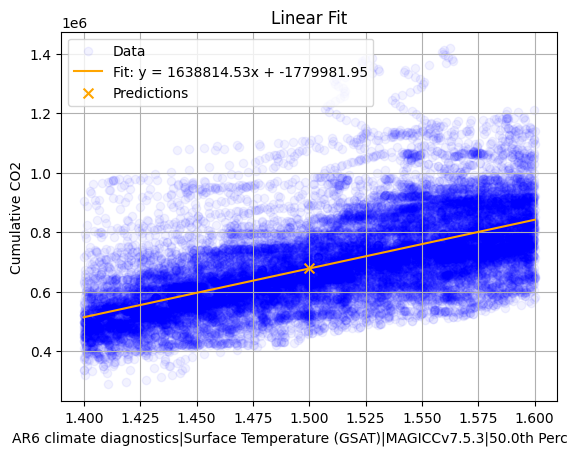

{2: 1583389.5174112436, 1.5: 678239.8489586506}

In [21]:
# does it desperately matter if we truncate this? 
cox_budget_magicc_trunc = fit_and_predict(
    useful_long[(useful_long[tempmagicc]<2.1) & (useful_long[tempmagicc]>1.9)], 
    tempmagicc, cumco2, [2]
)
cox_budget_magicc_trunc[1.5] = fit_and_predict(
    useful_long[(useful_long[tempmagicc]<1.6) & (useful_long[tempmagicc]>1.4)], 
    tempmagicc, cumco2, [1.5]
)[1.5]
cox_budget_magicc_trunc

In [22]:
(cox_budget_magicc_trunc[1.5] - cox_budget_magicc_unround[1.5])/cox_budget_magicc_unround[1.5]
# Makes no difference to results

0.0008243049512017228

In [23]:
(cox_budget_magicc_trunc[2] - cox_budget_magicc_unround[2])/cox_budget_magicc_unround[2]
# Makes no difference to results

0.0006345175255766261

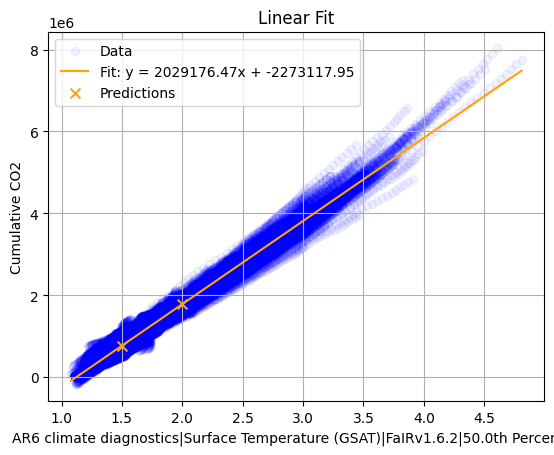

{1.5: 770646.7572390549, 2.0: 1785234.9944360098}

In [24]:
cox_budget_fair_unround = fit_and_predict(useful_long, tempfair, cumco2, temps_of_int)
cox_budget_fair_unround

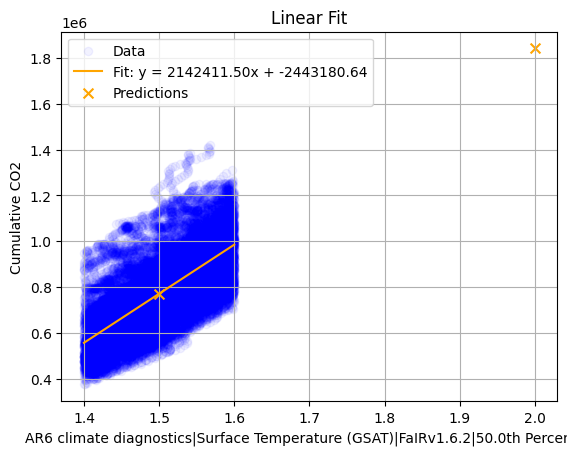

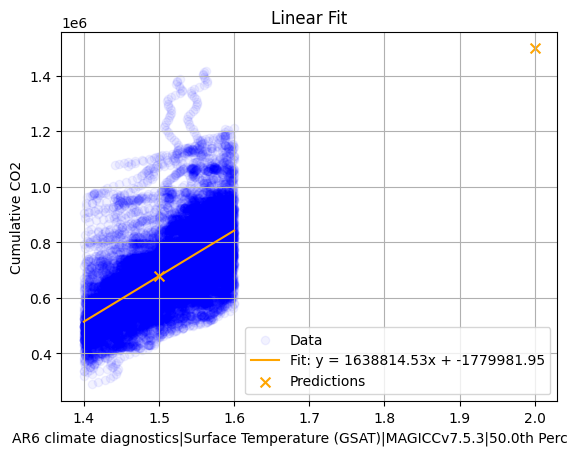

{1.5: 678239.8489586506, 2.0: 1497647.1160727907}

In [25]:
cox_budget_fair_trunc = fit_and_predict(useful_long[(useful_long[tempfair]<1.6) & (useful_long[tempfair]>1.4)], tempfair, cumco2, temps_of_int)
cox_budget_fair_trunc
cox_budget_magicc_trunc = fit_and_predict(useful_long[(useful_long[tempmagicc]<1.6) & (useful_long[tempmagicc]>1.4)], tempmagicc, cumco2, temps_of_int)
cox_budget_magicc_trunc

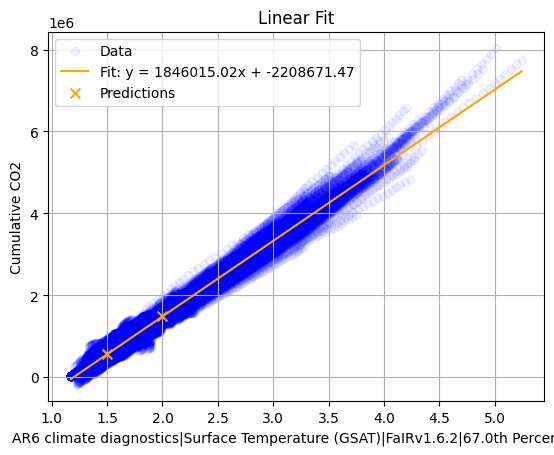

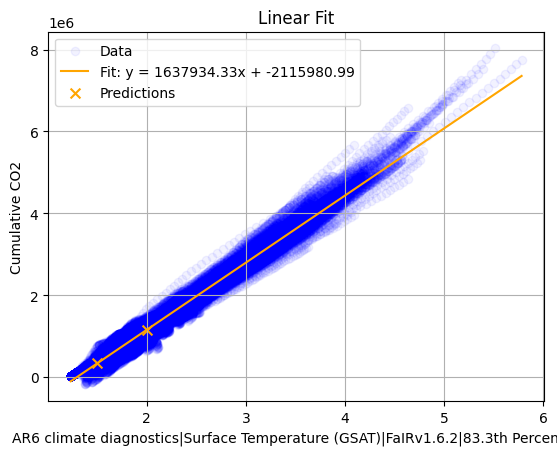

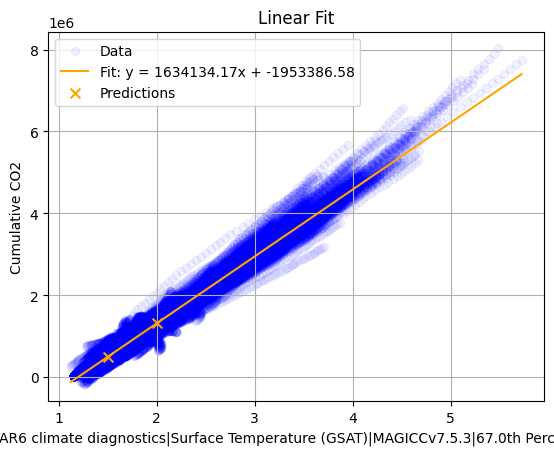

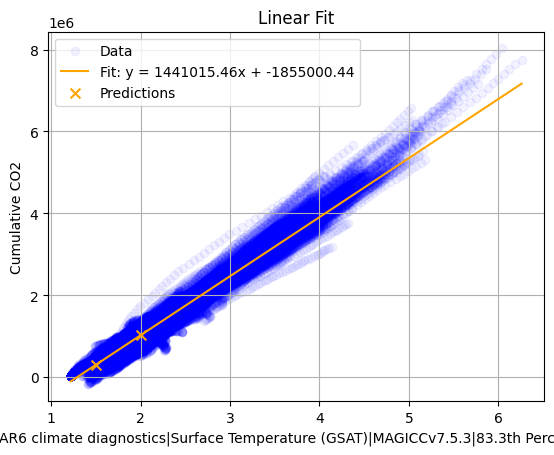

In [26]:
cox_budget_fair_unround66 = fit_and_predict(useful_long, tempfair66, cumco2, temps_of_int)
cox_budget_fair_unround83 = fit_and_predict(useful_long, tempfair83, cumco2, temps_of_int)
cox_budget_magicc_unround66 = fit_and_predict(useful_long, tempmagicc66, cumco2, temps_of_int)
cox_budget_magicc_unround83 = fit_and_predict(useful_long, tempmagicc83, cumco2, temps_of_int)

In [27]:
useful_long

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.111952                                 
                                                2016                                           1.140040                                 
                                                2017                                           1.167576                                 
                                                2018                                           1.193959                                 
                                                2019                                           1.218368                                 
...                                                                                                 ...                                 
WITCH-GLOBIOM 4.4 CD-LINKS_NoPolicy      World  2096                                           3.593418                                 
                                                2097                                           3.622228                                 
                                                2098                                           3.650265                                 
                                                2099                                           3.679157                                 
                                                2100                                           3.710858                                 

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|67.0th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.171397                                 
                                                2016                                           1.200596                                 
                                                2017                                           1.227560                                 
                                                2018                                           1.255157                                 
                                                2019                                           1.281616                                 
...                                                                                                 ...                                 
WITCH-GLOBIOM 4.4 CD-LINKS_NoPolicy      World  2096                                           3.906194                                 
                                                2097                                           3.935994                                 
                                                2098                                           3.966350                                 
                                                2099                                           3.997770                                 
                                                2100                                           4.032936                                 

variable                                              AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|83.3th Percentile  \
model             scenario               region year                                                                                    
AIM/CGE 2.0       ADVANCE_2020_1.5C-2100 World  2015                                           1.231521                                 
                         

In [28]:
# We should subtract emissions from 2015-2019 inclusive to make this 
# comparable with RCB calculations elsewhere
# From Global Carbon Project: 55.25 Gg C = 202.4 GtCO2
offset_emissions = 202400

In [29]:
# Present a list of values for the exceedance table for FaIR:
# 50% 1.5C, 83% 2C, 66% 2C, 50% 2C
print("For FaIR:")
((np.array([
    cox_budget_fair_unround[1.5], cox_budget_fair_unround83[2.0], cox_budget_fair_unround66[2.0], cox_budget_fair_unround[2.0]
])-offset_emissions)/1000).round(-1)

For FaIR:


array([ 570.,  960., 1280., 1580.])

In [30]:
print("For MAGICC:")
((np.array([
    cox_budget_magicc_unround[1.5], cox_budget_magicc_unround83[2.0], cox_budget_magicc_unround66[2.0], cox_budget_magicc_unround[2.0]
])-offset_emissions)/1000).round(-1)

For MAGICC:


array([ 480.,  820., 1110., 1380.])

# Now compare this to calculating using the peak temperature

In [31]:
# We only want to work with scenarios reaching net zero:
valid_index = (
    useful_long.xs(2100, level="year")
      .loc[lambda x: x["Emissions|CO2"] < 0]
      .index
)
useful_long_filtered = useful_long[useful_long.index.droplevel("year").isin(valid_index)]

In [32]:
# Calculate the max temp and cumulative CO2 for each scenario
useful_long_max = useful_long_filtered.groupby(["model", "scenario", "region"]).max()

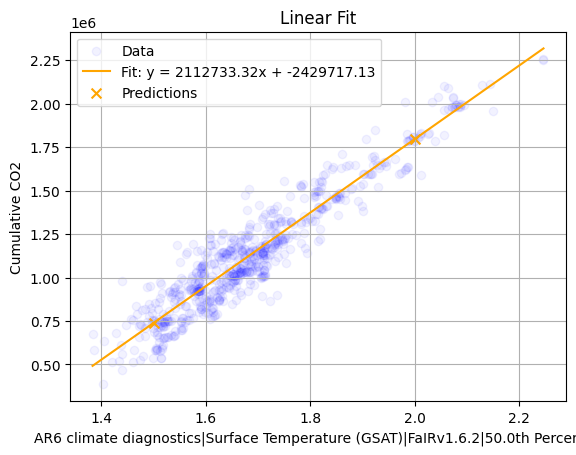

{1.5: 739382.8477712641, 2.0: 1795749.5080471844}

In [33]:
# Get the untruncated budgets first to compare
emulator_fair_budget = fit_and_predict(useful_long_max, tempfair, cumco2, temps_of_int)
emulator_fair_budget

[725774.472133342, 1776069.301383172]

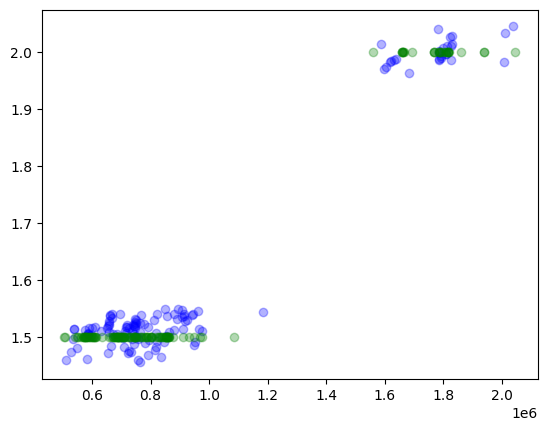

In [34]:
fit_around_window_with_correction(useful_long_max, [1.5, 2.0], 0.05, cumco2, [tempfair, tempfair], 0.45*1e-6)

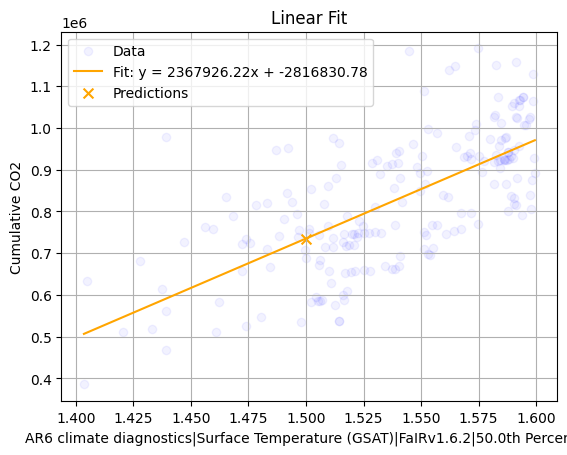

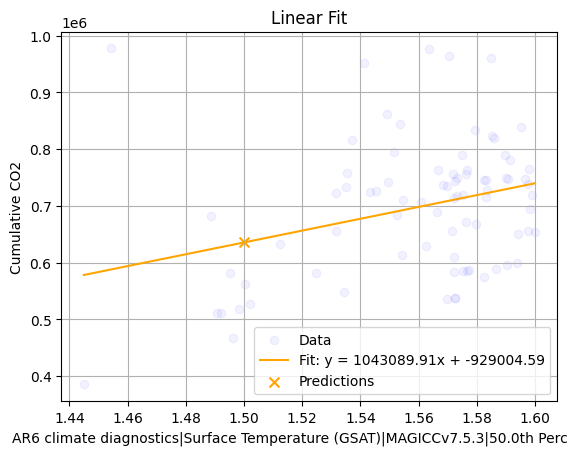

In [35]:
fair15budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempfair]<1.6)&(useful_long_max[tempfair]>1.4)], tempfair, cumco2, [1.5]
)
magicc15budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempmagicc]<1.6)&(useful_long_max[tempmagicc]>1.4)], tempmagicc, cumco2, [1.5]
)

In [36]:
fair15budget

{1.5: 735058.5478956643}

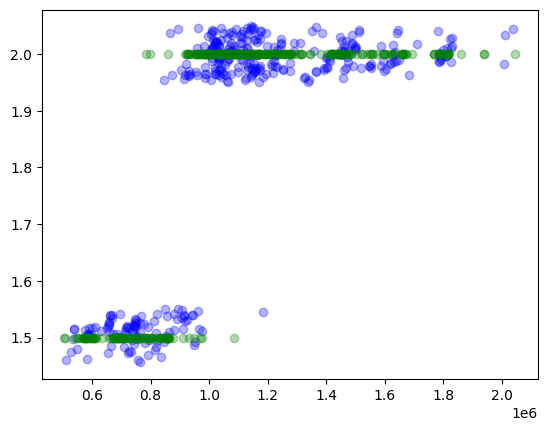

In [37]:
fairbudget_corrected = fit_around_window_with_correction(
    useful_long_max, 
    [1.5, 2.0, 2.0, 2.0], 
    0.05, 
    cumco2, 
    [tempfair, tempfair83, tempfair66, tempfair], 
    0.45 * 1e-6
)

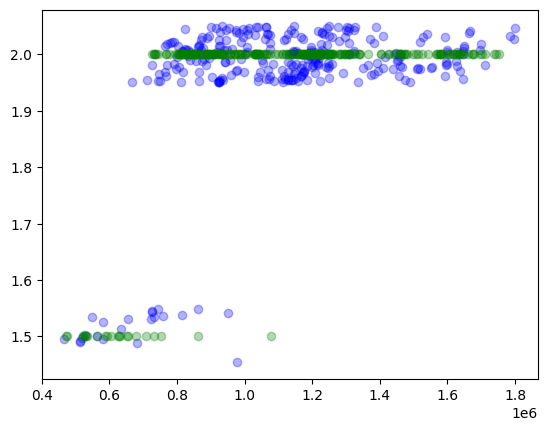

In [38]:
magiccbudget_corrected = fit_around_window_with_correction(
    useful_long_max, 
    [1.5, 2.0, 2.0, 2.0], 
    0.05, 
    cumco2, 
    [tempmagicc, tempmagicc83, tempmagicc66, tempmagicc], 
    0.45 * 1e-6
)

In [39]:
fair15budget

{1.5: 735058.5478956643}

In [40]:
fairbudget_corrected

[725774.472133342, 1091596.094071657, 1472401.9250882322, 1776069.301383172]

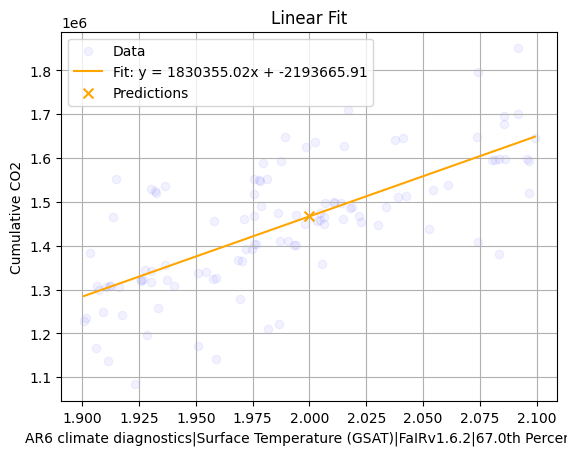

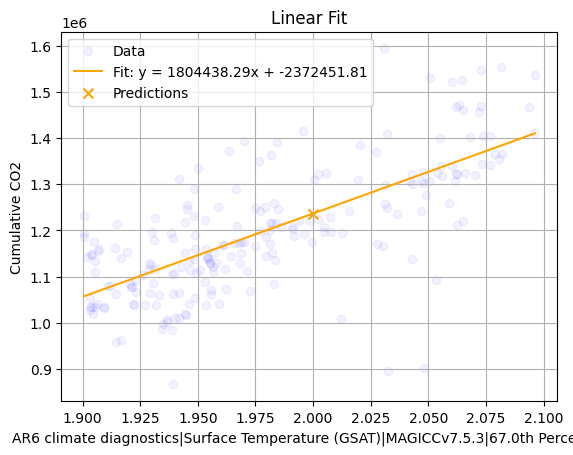

{2.0: 1236424.7782614282}

In [41]:
fair2C66budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempfair66]<2.1)&(useful_long_max[tempfair66]>1.9)], tempfair66, cumco2, [2.0]
)
fair2C66budget
magicc2C66budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempmagicc66]<2.1)&(useful_long_max[tempmagicc66]>1.9)], tempmagicc66, cumco2, [2.0]
)
magicc2C66budget

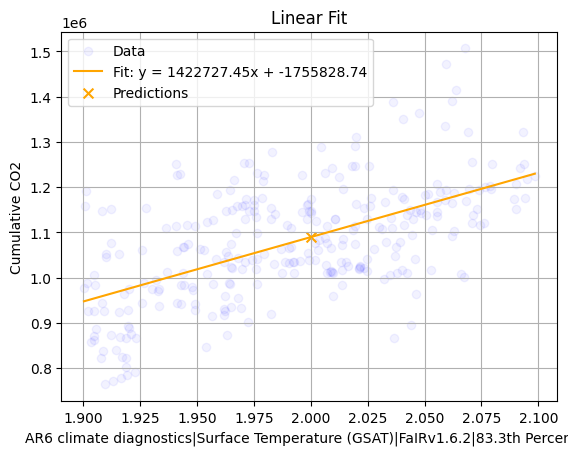

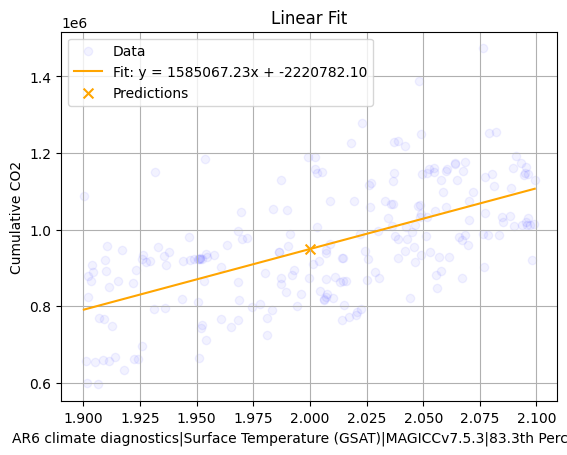

{2.0: 949352.370595309}

In [42]:
fair2C83budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempfair83]<2.1)&(useful_long_max[tempfair83]>1.9)], tempfair83, cumco2, [2.0]
)
fair2C83budget
magicc2C83budget = fit_and_predict(
    useful_long_max[(useful_long_max[tempmagicc83]<2.1)&(useful_long_max[tempmagicc83]>1.9)], tempmagicc83, cumco2, [2.0]
)
magicc2C83budget

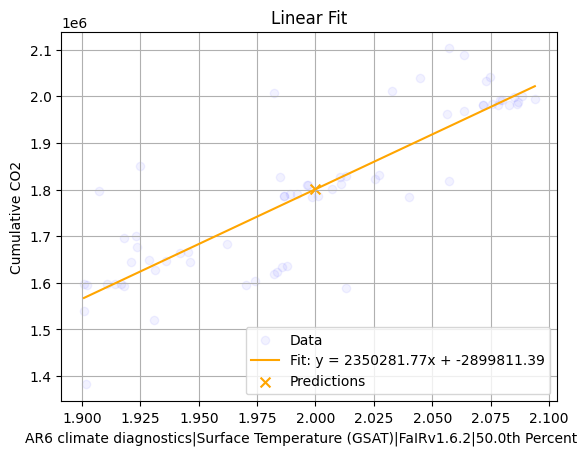

{2.0: 1800752.154267949}


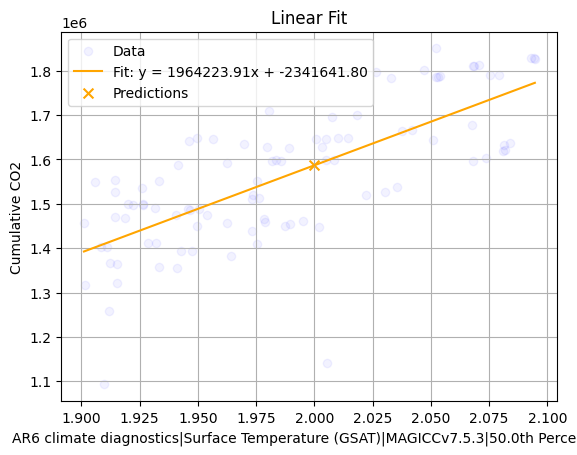

{2.0: 1586806.021671948}

In [43]:
fair2Cbudget = fit_and_predict(
    useful_long_max[(useful_long_max[tempfair]<2.1) & (useful_long_max[tempfair]>1.9)], tempfair, cumco2, [2.0]
)
print(fair2Cbudget)
magicc2Cbudget = fit_and_predict(
    useful_long_max[(useful_long_max[tempmagicc]<2.1) & (useful_long_max[tempmagicc]>1.9)], tempmagicc, cumco2, [2.0]
)
magicc2Cbudget

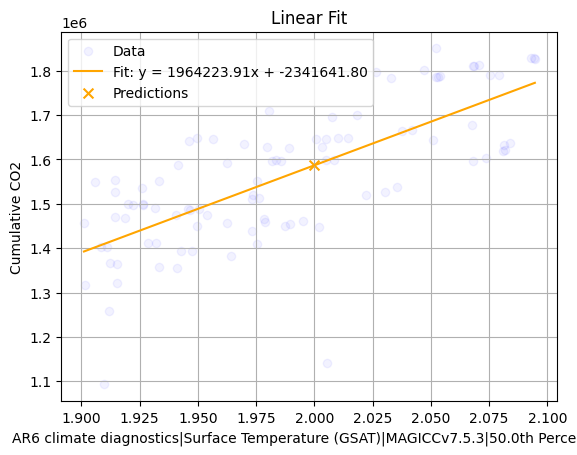

{2.0: 1586806.021671948}

In [44]:
best_magicc_2C = fit_and_predict(useful_long_max[(useful_long_max[tempmagicc]<2.1)&(useful_long_max[tempmagicc]>1.9)], tempmagicc, cumco2, [2.0])
best_magicc_2C

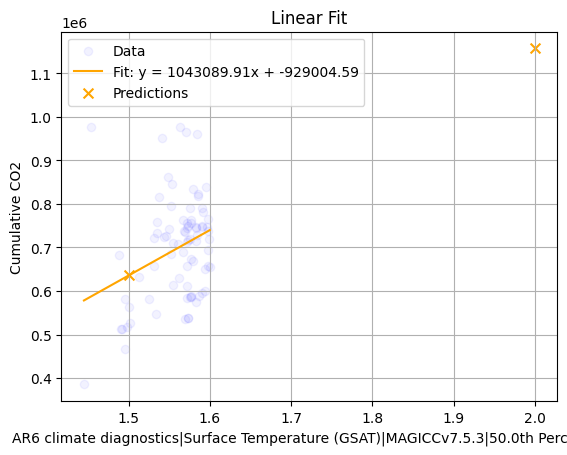

{1.5: 635630.2683478248, 2.0: 1157175.2217943296}

In [45]:
best_magicc_1p5C = fit_and_predict(useful_long_max[(useful_long_max[tempmagicc]<1.6)&(useful_long_max[tempmagicc]>1.4)], tempmagicc, cumco2, temps_of_int)
best_magicc_1p5C

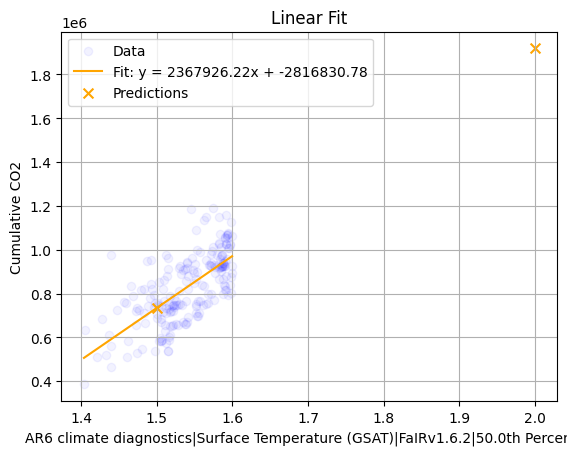

{1.5: 735058.5478956643, 2.0: 1919021.6588321114}

In [46]:
best_fair_1p5C = fit_and_predict(useful_long_max[(useful_long_max[tempfair]<1.6)&(useful_long_max[tempfair]>1.4)], tempfair, cumco2, temps_of_int)
best_fair_1p5C

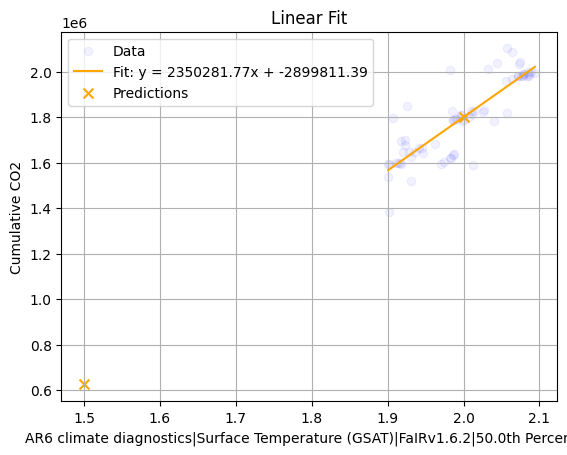

{1.5: 625611.2682320233, 2.0: 1800752.154267949}

In [47]:
best_fair_2C = fit_and_predict(useful_long_max[(useful_long_max[tempfair]<2.1)&(useful_long_max[tempfair]>1.9)], tempfair, cumco2, temps_of_int)
best_fair_2C

In [48]:
# Present values in convenient format for paper 
# for FaIR, if not correcting for exact warming:
# 50% 1.5C, 83% 2C, 66% 2C, 50% 2C
((np.array([
    fair15budget[1.5], fair2C83budget[2.0], fair2C66budget[2.0], fair2Cbudget[2.0]
])-offset_emissions)/1000)

array([ 532.6585479 ,  887.22617122, 1264.64412499, 1598.35215427])

In [49]:
# And for MAGICC:
# 50% 1.5C, 83% 2C, 66% 2C, 50% 2C
[int(x) for x in ((np.array([
    magicc15budget[1.5], magicc2C83budget[2.0], magicc2C66budget[2.0], magicc2Cbudget[2.0]
])-offset_emissions)/1000).round(-1)]

[430, 750, 1030, 1380]

In [50]:
# And similarly, if correcting for exact warming, for FaIR:
[int(((i - offset_emissions) / 1000).round(-1)) for i in fairbudget_corrected]

[520, 890, 1270, 1570]

In [51]:
# And MAGICC
[int(((i - offset_emissions) /  1000).round(-1)) for i in magiccbudget_corrected]

[430, 740, 1030, 1380]

# Calculate TCRE_eff for scenarios:

In [52]:
c1useful = useful.filter(Category=["C1"])
c1_useful_long = make_long(
    c1useful.filter(
        year=range(2015, 2020), keep=False
    ).timeseries().reset_index().drop(columns=["unit"])
)
c1_useful_long[cumco2] = c1_useful_long.groupby(["model", "scenario", "region"])[co2].cumsum()
c1_useful_long = c1_useful_long.reset_index("year")

In [53]:
# Calculate the TCRE for each C1 scenario over the 50 year period starting in 2020
timespan = 30
# Emissions are in Mt, we want TCRE in units of K/1000 Gt
MAGICCc1TCREs = (
    c1_useful_long[c1_useful_long.year==2020+timespan][tempmagicc] - c1_useful_long[c1_useful_long.year==2020][tempmagicc]
) / c1_useful_long[c1_useful_long.year==2020+timespan][cumco2] * 1000000
FaIRc1TCREs = (
    c1_useful_long[c1_useful_long.year==2020+timespan][tempfair] - c1_useful_long[c1_useful_long.year==2020][tempfair]
) / c1_useful_long[c1_useful_long.year==2020+timespan][cumco2] * 1000000

In [54]:
c4useful = useful.filter(Category=["C4"])
c4_useful_long = make_long(
    c4useful.filter(
        year=range(2015, 2020), keep=False
    ).timeseries().reset_index().drop(columns=["unit"])
)
c4_useful_long[cumco2] = c4_useful_long.groupby(["model", "scenario", "region"])[co2].cumsum()
c4_useful_long = c4_useful_long.reset_index("year")

In [55]:
MAGICCc4TCREs = (
    c4_useful_long[c4_useful_long.year==2020+timespan][tempmagicc] - c4_useful_long[c4_useful_long.year==2020][tempmagicc]
) / c4_useful_long[c4_useful_long.year==2020+timespan][cumco2] * 1000000
FaIRc4TCREs = (
    c4_useful_long[c4_useful_long.year==2020+timespan][tempfair] - c4_useful_long[c4_useful_long.year==2020][tempfair]
) / c4_useful_long[c4_useful_long.year==2020+timespan][cumco2] * 1000000

# Plot the effective TCRE data from Yona for comparison

In [56]:
aera = pd.read_csv("./input/AERA-MIP_warming_cumemissions_20202050.csv")
aera15 = "1.5ºC"  # Record column name 
aera20 = "2.0ºC"
# The bottom lines are summary info, we can skip this
aera = aera[:-3]
aera

,model,1.5ºC,2.0ºC,mean of 1.5ºC and 2.0ºC
0,CESM2,3.629182,1.769097,2.699139
1,EC-Earth3-CC,4.059904,2.468384,3.264144
2,NASA-GISS.GISS-E2-1-G-CC,7.417513,2.486212,4.951863
3,GFDL-ESM2M,0.777563,0.879048,0.828305
4,GFDL-ESM4,0.582515,1.105503,0.844009
5,IPSL-CM6-LR-ESMCO2,1.267069,1.595520,1.431294
6,MIROC-ES2L,4.448006,1.817784,3.132895
7,MPI-ESM1-2-LR,1.105083,1.234267,1.169675
8,NorESM2-LM,1.582605,1.371974,1.477289
9,Bern3D-LPX,2.842495,1.844675,2.343585


In [57]:
-6.22/3.664

-1.697598253275109

(array([1., 0., 0., 0., 1., 5., 1., 3., 0., 1.]),
 array([-1.69896034, -1.32662127, -0.9542822 , -0.58194312, -0.20960405,
         0.16273502,  0.53507409,  0.90741316,  1.27975224,  1.65209131,
         2.02443038]),
 <BarContainer object of 10 artists>)

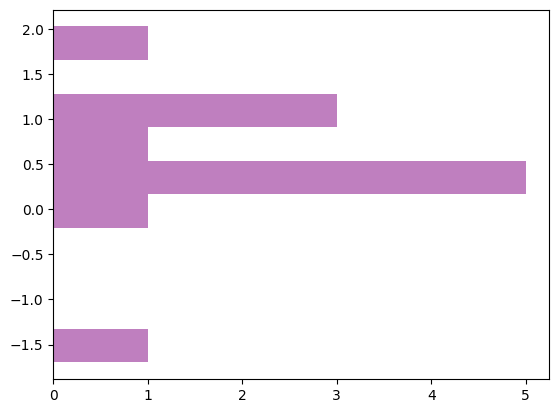

In [58]:
plt.hist(aera[aera15]/3.664, orientation='horizontal', color="purple", alpha=0.5, label="AERA-MIP")

Text(0.5, 1.0, '2.0°C scenarios 2020-2050')

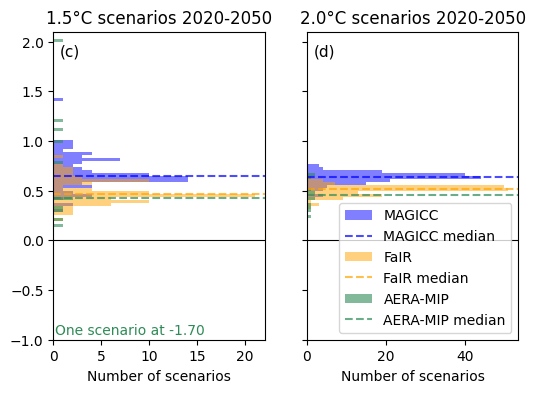

In [90]:
magiccc = "blue"
fairc = "orange"
aerac = "seagreen"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 4), sharey=True)
bins = np.arange(-1.901, 2.2, 0.03)
ax1.hist(MAGICCc1TCREs, orientation='horizontal', alpha=0.5, label="MAGICC", bins=bins, color=magiccc)
ax1.axhline(MAGICCc1TCREs.median(), linestyle="--", label="MAGICC median", alpha=0.7, color=magiccc)
ax1.hist(FaIRc1TCREs, orientation='horizontal', alpha=0.5, label="FaIR", bins=bins, color=fairc)
ax1.axhline(FaIRc1TCREs.median(), linestyle="--", label="FaIR median", alpha=0.7, color=fairc)
# AERA-MIP data must be fixed to units of CO2 instead of C
ax1.hist(aera[aera15]/3.664, orientation='horizontal', color=aerac, alpha=0.6, label="AERA-MIP", bins=bins)
ax1.axhline((aera[aera15]/3.664).median(), linestyle="--", label="AERA-MIP median", alpha=0.7, color=aerac)
ax1.set_ylim(-1.0, 2.1)
ax1.set_xlabel("Number of scenarios")
ax2.hist(MAGICCc4TCREs, orientation='horizontal', alpha=0.5, label="MAGICC", bins=bins, color=magiccc)
ax2.axhline(MAGICCc4TCREs.median(), linestyle="--", label="MAGICC median", alpha=0.7, color=magiccc)
ax2.hist(FaIRc4TCREs, orientation='horizontal', alpha=0.5, label="FaIR", bins=bins,color=fairc)
ax2.axhline(FaIRc4TCREs.median(), linestyle="--", label="FaIR median", alpha=0.7, color=fairc)
ax2.hist(aera[aera20]/3.664, orientation='horizontal', color=aerac, alpha=0.6, label="AERA-MIP", bins=bins)
ax2.axhline((aera[aera20]/3.664).median(), linestyle="--", label="AERA-MIP median", alpha=0.7, color=aerac)
ax2.legend(loc='lower right')
ax2.set_xlabel("Number of scenarios")
ax1.text(0.03, 0.96, "(c)", transform=ax1.transAxes,
         fontsize=11, va="top", ha="left")
ax2.text(0.03, 0.96, "(d)", transform=ax2.transAxes,
         fontsize=11, va="top", ha="left")
ax1.axhline(0, color="black", linewidth=0.8)
ax2.axhline(0, color="black", linewidth=0.8)
ax1.set_title("1.5°C scenarios 2020-2050")
ax1.text(s="One scenario at -1.70", c=aerac, x=0.2, y=-0.95)
ax2.set_title("2.0°C scenarios 2020-2050")

In [91]:
import matplotlib.gridspec as gridspec

NameError: name 'data' is not defined

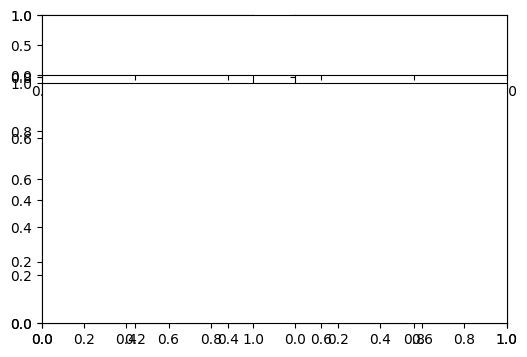

In [92]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 4), sharey=True)
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 4], hspace=0.05)

ax_box = fig.add_subplot(gs[0])
ax_hist = fig.add_subplot(gs[1], sharex=ax_box)

# box plot
ax_box.boxplot(data.dropna(), vert=False, widths=0.6,
               flierprops=dict(marker=".", markersize=4))
ax_box.set_yticks([])
ax_box.tick_params(labelbottom=False)
for spine in ["top", "right", "left"]:
    ax_box.spines[spine].set_visible(False)
ax1.hist(MAGICCc1TCREs, orientation='horizontal', alpha=0.5, label="MAGICC", bins=bins)
ax1.hist(FaIRc1TCREs, orientation='horizontal', alpha=0.5, label="FaIR", bins=bins)
# AERA-MIP data must be fixed to units of CO2 instead of C
ax1.hist(aera[aera15]/3.664, orientation='horizontal', color="purple", alpha=0.5, label="AERA-MIP", bins=bins)
ax1.legend()
ax1.set_ylim(-1.0, 2.1)
ax1.set_xlabel("Number of scenarios")
ax2.hist(MAGICCc4TCREs, orientation='horizontal', alpha=0.5, label="MAGICC", bins=bins)
ax2.hist(FaIRc4TCREs, orientation='horizontal', alpha=0.5, label="FaIR", bins=bins)
ax2.hist(aera[aera20]/3.664, orientation='horizontal', color="purple", alpha=0.5, label="AERA-MIP", bins=bins)
ax2.legend()
ax2.set_xlabel("Number of scenarios")
ax1.text(0.03, 0.96, "(c)", transform=ax1.transAxes,
         fontsize=11, va="top", ha="left")
ax2.text(0.03, 0.96, "(d)", transform=ax2.transAxes,
         fontsize=11, va="top", ha="left")
ax1.axhline(0, color="black", linewidth=0.8)
ax2.axhline(0, color="black", linewidth=0.8)
ax1.set_title("1.5°C scenarios 2020-2050")
ax1.text(s="One scenario at -1.70", c="purple", x=0.2, y=-0.95)
ax2.set_title("2.0°C scenarios 2020-2050")


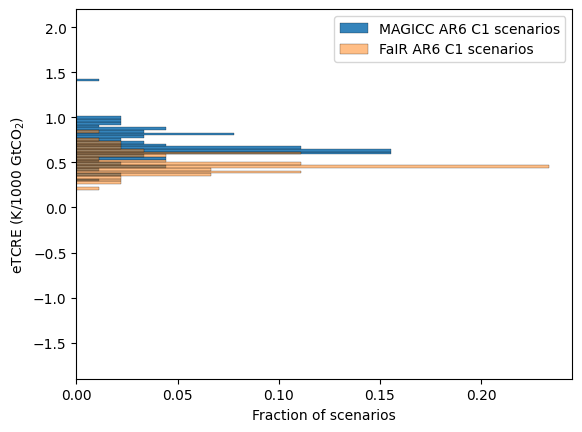

In [66]:
sns.histplot(y=MAGICCc1TCREs, bins=bins, stat="probability", label="MAGICC AR6 C1 scenarios", alpha=0.9,)
plt.xlabel("Fraction of scenarios")
plt.ylabel("eTCRE (K/1000 GtCO$_2$)")
sns.histplot(y=FaIRc1TCREs,alpha=0.5, bins=bins, stat="probability", label="FaIR AR6 C1 scenarios")
plt.ylim(-1.9, 2.2)
plt.legend()

In [ ]:
plt.scatter(x=[1/12]*12, y=aera[aera15]/3.664, label="AERA-MIP scenarios", alpha=0.4)

In [ ]:
aera[aera15]/3.664